In [1]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

In [2]:
def load_image_from_txt(filename, shape):
    # Read all numbers from the file
    with open(filename, 'r') as f:
        data_str = f.read()

    # Convert string to list of integers
    data_list = list(map(int, data_str.split()))

    # Convert to numpy array``
    img_array = np.array(data_list, dtype=np.uint8)

    # Reshape to (height, width) or (height, width, channels) as needed
    img_array = img_array.reshape(shape)

    return img_array

def load_data_from_txt(filename, shape):
    # Read all numbers from the file
    with open(filename, 'r') as f:
        data_str = f.read()

    # Convert string to list of integers
    data_list = list(map(float, data_str.split()))

    # Convert to numpy array
    img_array = np.array(data_list, dtype=np.float64)

    # Reshape to (height, width) or (height, width, channels) as needed
    img_array = img_array.reshape(shape)

    return img_array

In [3]:
BASE_IMG = "image_data.txt"
LAB_IMG = "lab_image_data.txt"

IMG_SHAPE = (240, 320, 3)  # Example shape, adjust as needed

LENNA_SHAPE = (512, 512)  # Shape of Lenna image
LENNA_RGB_SHAPE = (512, 512, 3)  # Shape of Lenna image

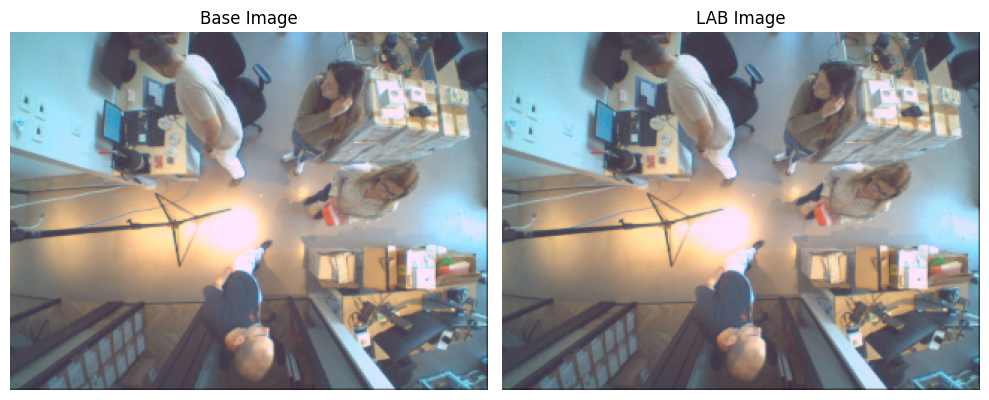

In [4]:
base_image = load_image_from_txt(BASE_IMG, IMG_SHAPE)
lab_image = load_image_from_txt(LAB_IMG, IMG_SHAPE)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(base_image)
plt.title('Base Image')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(lab_image)
plt.title('LAB Image')
plt.axis('off')
plt.tight_layout()
plt.show()

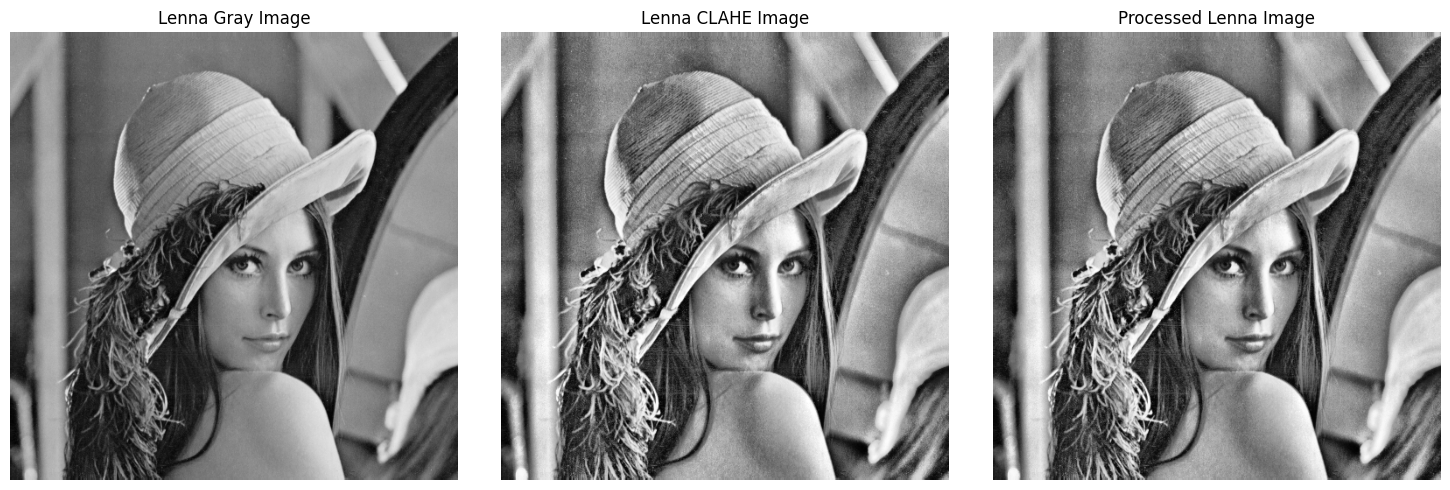

In [5]:
lenna_gray = load_image_from_txt('lenna_gray.txt', LENNA_SHAPE)

clahe_img = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
lenna_clahe = clahe_img.apply(lenna_gray)

lenna_processed = load_image_from_txt('lenna_processed.txt', LENNA_SHAPE)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(lenna_gray, cmap='gray')
plt.title('Lenna Gray Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(lenna_clahe, cmap='gray')
plt.title('Lenna CLAHE Image')
plt.axis('off')
plt.tight_layout()

plt.subplot(1, 3, 3)
plt.imshow(lenna_processed, cmap='gray')
plt.title('Processed Lenna Image')
plt.axis('off')
plt.tight_layout()


2 0.6055183410644531


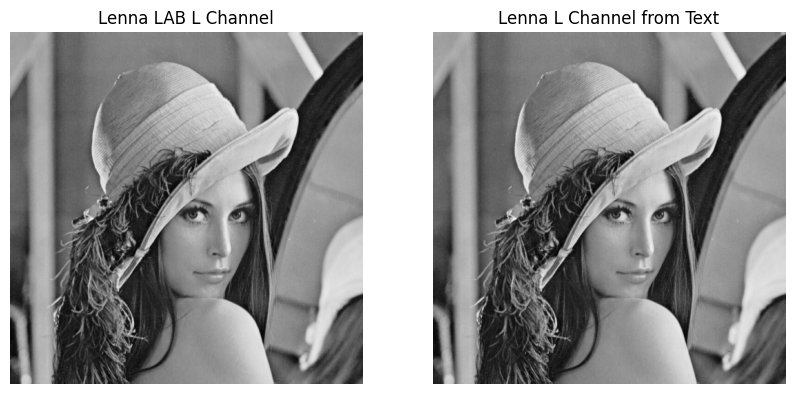

In [6]:
lenna_l = load_image_from_txt('lenna_l_channel.txt', LENNA_SHAPE)
lena = cv2.imread('lenna.png')
lena_lab = cv2.cvtColor(lena, cv2.COLOR_BGR2LAB)

diff = np.abs(lenna_l.astype(int) - lena_lab[:, :, 0])
print(diff.max(), diff.mean())

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(lena_lab[:, :, 0], cmap='gray')
plt.title('Lenna LAB L Channel')
plt.axis('off')
plt.subplot(1, 2, 2)

plt.imshow(lenna_l, cmap='gray')
plt.title('Lenna L Channel from Text')
plt.axis('off');

(-0.5, 511.5, 511.5, -0.5)

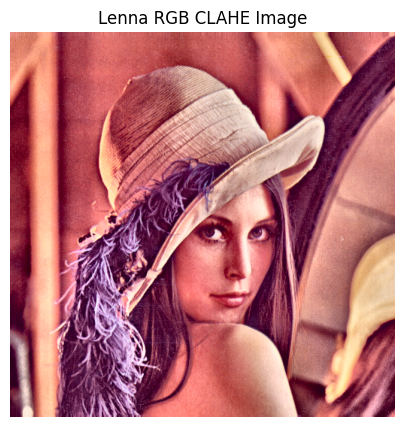

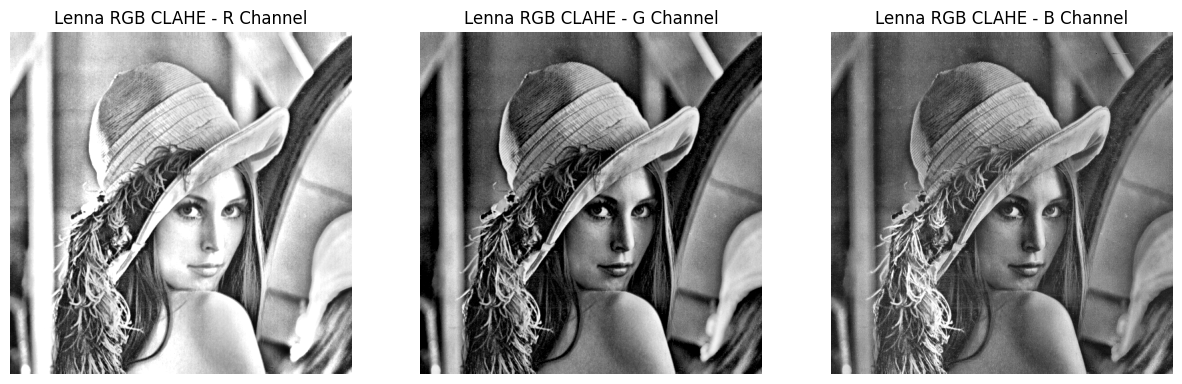

In [7]:
lenna_rgb_clahe = load_image_from_txt('lenna_rgb_clahe.txt', LENNA_RGB_SHAPE)

plt.figure(figsize=(5, 5))
plt.imshow(lenna_rgb_clahe)
plt.title('Lenna RGB CLAHE Image')
plt.axis('off');

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(lenna_rgb_clahe[:, :, 0], cmap='gray')
plt.title('Lenna RGB CLAHE - R Channel')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(lenna_rgb_clahe[:, :, 1], cmap='gray')
plt.title('Lenna RGB CLAHE - G Channel')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(lenna_rgb_clahe[:, :, 2], cmap='gray')
plt.title('Lenna RGB CLAHE - B Channel')
plt.axis('off')

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


(-0.5, 511.5, 511.5, -0.5)

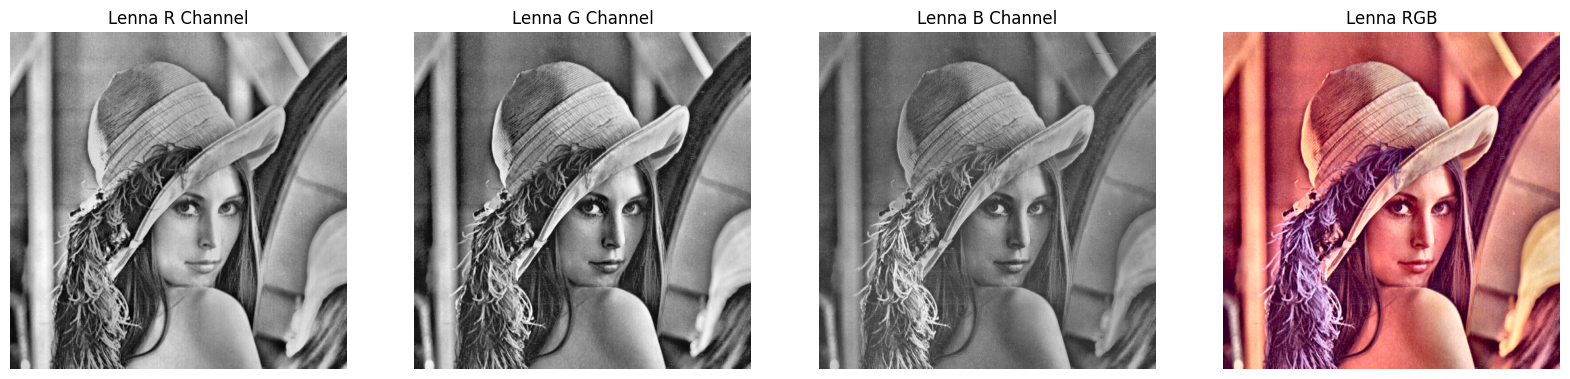

In [8]:
lena_r_channel = load_data_from_txt('lenna_r_channel.txt', LENNA_SHAPE)
lena_g_channel = load_data_from_txt('lenna_g_channel.txt', LENNA_SHAPE)
lena_b_channel = load_data_from_txt('lenna_b_channel.txt', LENNA_SHAPE)

lena_composed = np.stack((lena_r_channel, lena_g_channel, lena_b_channel), axis=-1)

plt.figure(figsize=(20, 5))
plt.subplot(1, 4, 1)
plt.imshow(lena_r_channel, cmap='gray')
plt.title('Lenna R Channel')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(lena_g_channel, cmap='gray')
plt.title('Lenna G Channel')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(lena_b_channel, cmap='gray')
plt.title('Lenna B Channel')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(lena_composed)
plt.title('Lenna RGB')
plt.axis('off')


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


(-0.5, 511.5, 511.5, -0.5)

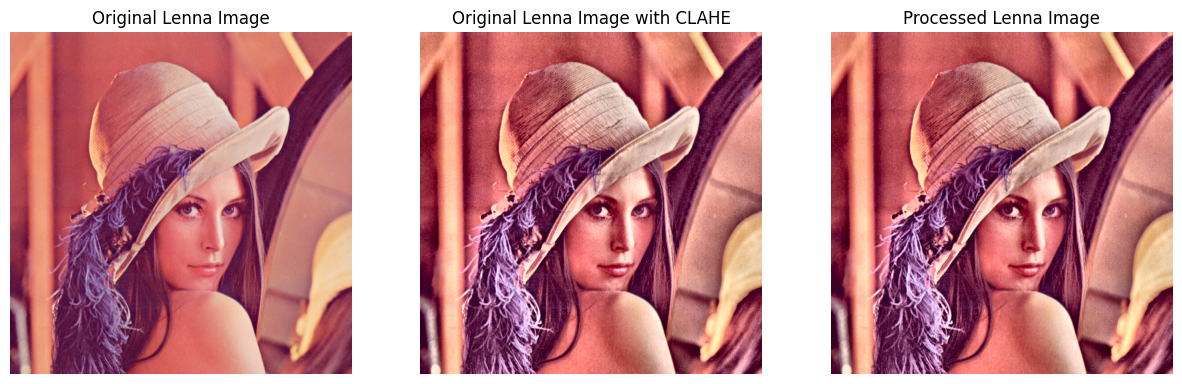

In [9]:
original_img = cv2.imread('lenna.png')
original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)

original_img_lab = cv2.cvtColor(original_img, cv2.COLOR_RGB2LAB)
img_clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
original_img_clahe = img_clahe.apply(original_img_lab[:, :, 0])

original_img_lab[:, :, 0] = original_img_clahe

original_img_rgb = cv2.cvtColor(original_img_lab, cv2.COLOR_LAB2RGB)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(original_img)
plt.title('Original Lenna Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(original_img_rgb)
plt.title('Original Lenna Image with CLAHE')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(lena_composed)
plt.title('Processed Lenna Image')

plt.axis('off')

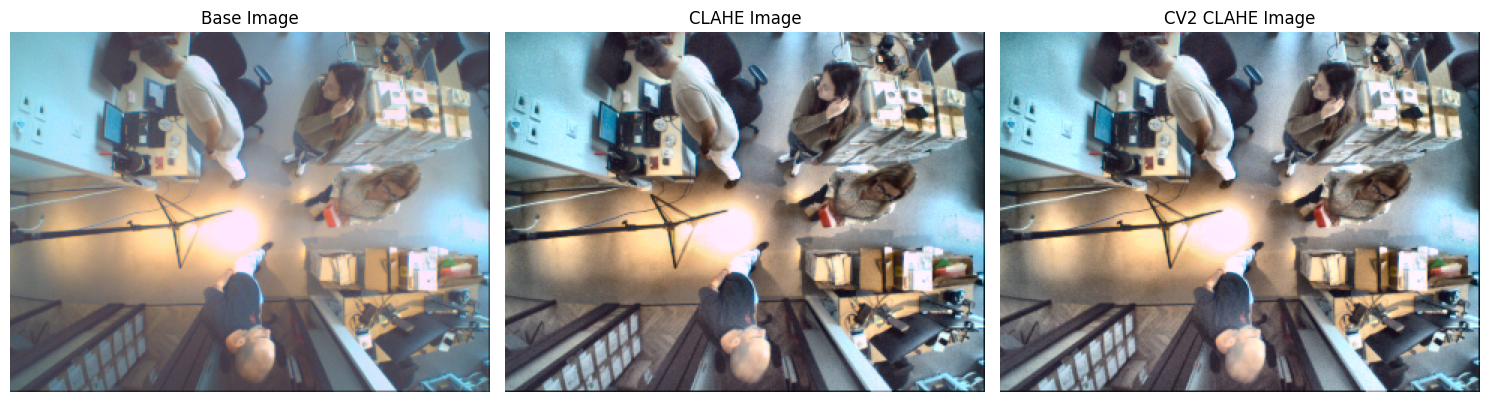

In [11]:
base_image = load_image_from_txt(BASE_IMG, IMG_SHAPE)
clahe_image = load_image_from_txt("output_data.txt", IMG_SHAPE)

original_img_lab = cv2.cvtColor(base_image, cv2.COLOR_RGB2LAB)
img_clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
original_img_clahe = img_clahe.apply(original_img_lab[:, :, 0])

original_img_lab[:, :, 0] = original_img_clahe

original_img_rgb = cv2.cvtColor(original_img_lab, cv2.COLOR_LAB2RGB)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(base_image)
plt.title('Base Image')
plt.axis('off')
plt.subplot(1, 3, 2)
plt.imshow(clahe_image)
plt.title('CLAHE Image')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(original_img_rgb)
plt.title('CV2 CLAHE Image')
plt.axis('off')

plt.tight_layout()
plt.show()

In [14]:
diff = np.abs(clahe_image.astype(int) - original_img_rgb)
diff.max(), diff.mean()

(21, 3.532890625)